# **Cargo las librerías necesarias**

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from scipy.cluster.hierarchy import dendrogram, linkage
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# **Montamos nuestro Google Drive**

In [ ]:
import sys
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# **Evitamos warnings**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# **Leo los archivos .py para usar funciones dadas en clase**


In [ ]:
sys.path.append(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Dia 1/Datos')
sys.path.append(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Datos parte 2')


# **Cargo las funciones que voy a utilizar**

In [ ]:
from FuncionesMineria import (glm, frec_variables_num, lm,)
from NuestrasFunciones import (scree_plot_kmeans, eval_model)

# **Cargo los datos**

In [ ]:
viviendas = pd.read_excel('/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Dia 1/Datos/VentaViviendas.xlsx')

# **Visualizo los datos de viviendas**

In [ ]:
viviendas

,year,month,price,Luxury,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,basement,yr_built,yr_renovated,lat,long
0,2014,7,653450,1,3,2.5,2070,-1,1.0,0,0,C,1540,1,1980,0,47.5936,-122.013
1,2014,6,710000,1,2,1.5,1640,-1,1.5,0,0,A,1540,1,1916,0,47.6624,-122.325
2,2014,10,780000,1,4,3.5,3720,-1,1.0,0,1,B,3720,0,2007,0,47.3216,-121.940
3,2014,12,795000,1,3,3.5,2260,-1,2.0,0,0,B,1880,1,2003,0,47.6422,-122.361
4,2014,10,399950,0,3,2.0,2050,-1,1.0,0,0,A,1170,1,1960,0,47.7447,-122.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,2015,2,370000,0,2,2.5,1390,1821,2.0,0,0,B,1180,1,2007,0,47.5537,-122.282
4996,2015,1,374950,0,4,2.0,1660,8160,1.0,0,0,B,1660,0,1974,0,47.4483,-122.129
4997,2015,2,234000,0,3,2.0,1480,8475,1.0,0,0,C,1480,0,1968,0,47.3126,-122.361
4998,2015,3,475000,0,3,3.0,2540,18900,1.0,0,0,B,1580,1,1978,0,47.7540,-122.144


### Pregunta 4:

In [ ]:
viviendas.describe().T

,count,mean,std,min,25%,50%,75%,max
year,5000.0,2014.316800,0.465275,2014.0000,2014.000000,2014.0000,2015.000000,2015.000
month,5000.0,6.589400,3.120377,1.0000,4.000000,6.0000,9.000000,12.000
price,5000.0,544129.100600,372986.940618,86500.0000,324937.500000,451000.0000,645000.000000,7062500.000
Luxury,5000.0,0.422800,0.494054,0.0000,0.000000,0.0000,1.000000,1.000
bedrooms,5000.0,3.624200,3.710165,0.0000,3.000000,3.0000,4.000000,70.000
bathrooms,5000.0,2.139500,0.867606,0.0000,1.500000,2.5000,2.500000,6.000
sqft_living,5000.0,2077.382000,916.477607,370.0000,1410.000000,1910.0000,2560.000000,10040.000
sqft_lot,5000.0,13732.479200,37581.443768,-1.0000,4500.000000,7312.0000,10284.250000,1164794.000
floors,5000.0,1.496400,0.541522,1.0000,1.000000,1.5000,2.000000,3.500
waterfront,5000.0,-0.012800,0.171587,-1.0000,0.000000,0.0000,0.000000,1.000


### Pregunta 5:

In [ ]:
viviendas['condition'].nunique()

5

### Pregunta 6:

In [ ]:
viviendas['waterfront'].value_counts()

,count
waterfront,
0,4852
-1,106
1,42


### Pregunta 7:

In [ ]:
frec_variables_num(viviendas, ['waterfront'])['waterfront']

,n,%
waterfront,,
0,4852,0.9704
-1,106,0.0212
1,42,0.0084


### Pregunta 8:

In [ ]:
lm(viviendas['price'], viviendas, ['lat'], [])['Modelo'].rsquared

np.float64(0.09071724374189338)

### Pregunta 9:

In [ ]:
lm(viviendas['price'], viviendas, ['sqft_living'], [])['Modelo'].params

,0
const,-61051.421461
sqft_living,291.318844


### Pregunta 10:

In [ ]:
np.exp(glm(viviendas['Luxury'], viviendas, ['sqft_living'], [])['Modelo'].coef_[0][0])

np.float64(1.0018655165919332)

### Pregunta 11:

In [ ]:
np.exp(0.4) - 1

np.float64(0.49182469764127035)

# **Cargo los nuevos datos**

In [ ]:
penguins = pd.read_excel('/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Datos parte 1/penguins.xlsx')

# **Visualizo los datos de penguins**

> Añadir blockquote



In [ ]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181,3750,Male
1,Adelie,Torgersen,39.5,17.4,186,3800,Female
2,Adelie,Torgersen,40.3,18.0,195,3250,Female
3,Adelie,Torgersen,36.7,19.3,193,3450,Female
4,Adelie,Torgersen,39.3,20.6,190,3650,Male
...,...,...,...,...,...,...,...
328,Gentoo,Biscoe,47.2,13.7,214,4925,Female
329,Gentoo,Biscoe,46.8,14.3,215,4850,Female
330,Gentoo,Biscoe,50.4,15.7,222,5750,Male
331,Gentoo,Biscoe,45.2,14.8,212,5200,Female


### Pregunta 21:

In [ ]:
columnas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = penguins[columnas].dropna()

In [ ]:
pca = PCA().fit(StandardScaler().fit_transform(X))
print(pca.explained_variance_ratio_ * 100)

[68.63389314 19.45292928  9.21606299  2.69711459]


### Pregunta 22:

In [ ]:
pca.explained_variance_ratio_.cumsum() * 100

array([ 68.63389314,  88.08682242,  97.30288541, 100.        ])

### Pregunta 24:

In [ ]:
matriz_correlaciones = pd.DataFrame(
    pca.components_.T * np.sqrt(pca.explained_variance_),
    columns=['PC1', 'PC2', 'PC3', 'PC4'],
    index=columnas
)

In [ ]:
matriz_correlaciones['PC1'].abs().idxmax()

'flipper_length_mm'

### Pregunta 25:

In [ ]:
matriz_correlaciones['PC2'].abs().idxmax()

'bill_depth_mm'

### Pregunta 26:

In [ ]:
(matriz_correlaciones.loc['bill_depth_mm', 'PC2'] ** 2) * 100

np.float64(49.47231456346317)

### Pregunta 31:

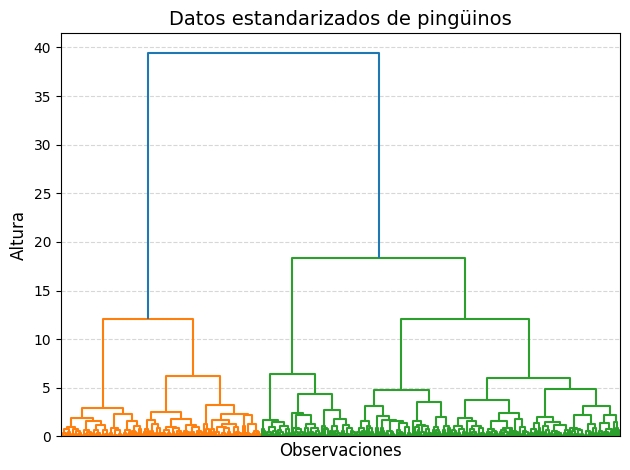

<Figure size 1200x600 with 0 Axes>

In [ ]:
X_escalada = StandardScaler().fit_transform(X)

matriz_enlace = linkage(X_escalada, method='ward')

dendrogram(
    matriz_enlace,
    no_labels=True,
    leaf_rotation=90.,
    color_threshold=0.7 * max(matriz_enlace[:, 2])
)
plt.title('Datos estandarizados de pingüinos', fontsize=14)
plt.xlabel('Observaciones', fontsize=12)
plt.ylabel('Altura', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.figure(figsize=(12, 6))
plt.show()

### Pregunta 32:

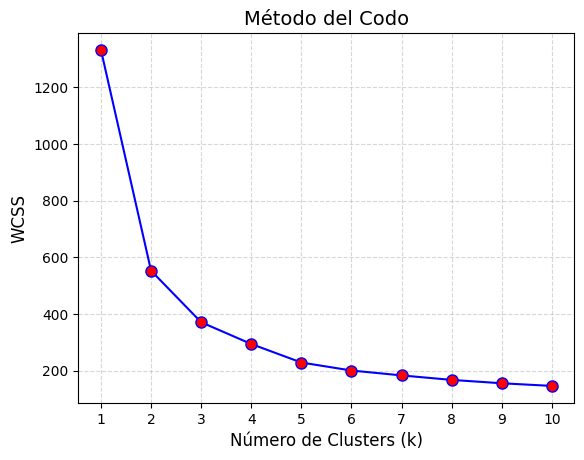

<Figure size 1000x600 with 0 Axes>

In [ ]:
WCSS = []
rango_k = range(1, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_escalada)
    WCSS.append(kmeans.inertia_)

plt.plot(rango_k, WCSS, 'bo-', markerfacecolor='red', markersize=8)
plt.title('Método del Codo', fontsize=14)
plt.xlabel('Número de Clusters (k)', fontsize=12)
plt.ylabel('WCSS', fontsize=12)
plt.xticks(rango_k)
plt.grid(True, linestyle='--', alpha=0.5)
plt.figure(figsize=(10, 6))
plt.show()

### Pregunta 33:

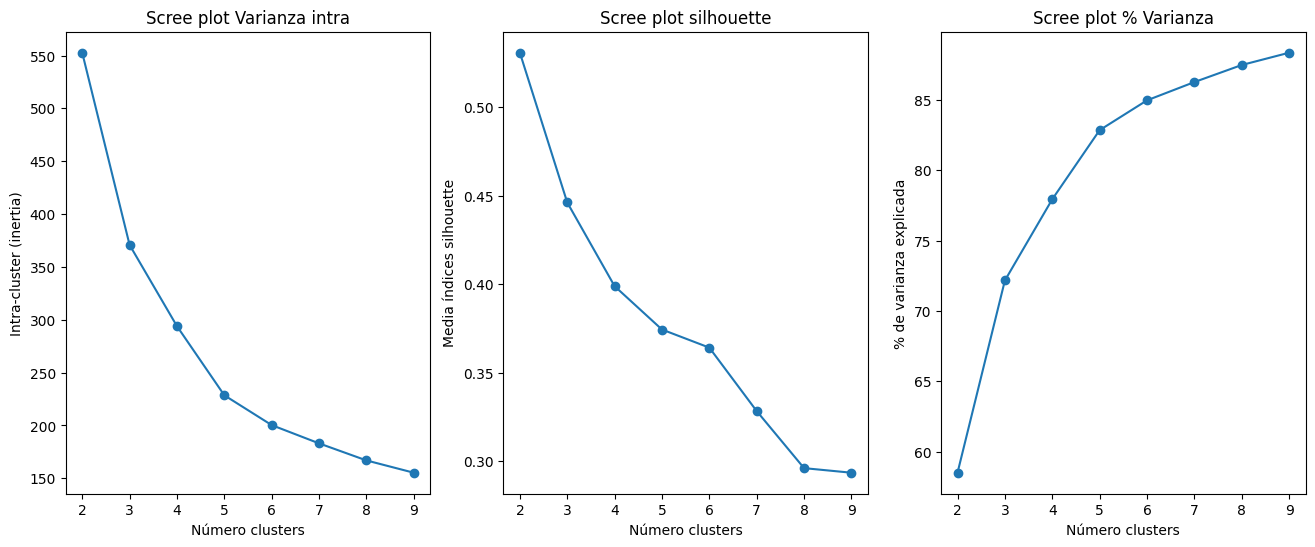

In [ ]:
columnas_numericas = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

datos_para_cluster = penguins[columnas_numericas]

scree_plot_kmeans(datos_para_cluster, n_max=10)

# **Cargo los nuevos datos**

In [ ]:
IPI = pd.read_excel(r'/content/drive/MyDrive/Documentación minería de datos y modelización predictiva - Elena Gavilán y Daniel Martín-20260123/Datos parte 3/IPI_Esp.xlsx')

# **Visualizo los datos de IPI**

In [ ]:
IPI

,Date,IPI Nacional
0,1975M01,70.658
1,1975M02,72.180
2,1975M03,75.732
3,1975M04,74.844
4,1975M05,74.210
...,...,...
534,2019M07,114.698
535,2019M08,85.929
536,2019M09,106.408
537,2019M10,114.592


# **Limpiamos los nombres de las columnas, convertimos las fechas y las ponemos como índice y definimos la frecuencia mensual**

In [ ]:
IPI.columns = IPI.columns.str.strip()

In [ ]:
IPI['Date'] = IPI['Date'].astype(str).str.strip().str.replace('M', '-')
IPI['Date'] = pd.to_datetime(IPI['Date'], format='%Y-%m')

In [ ]:
IPI.set_index('Date', inplace=True)
IPI.index.freq = 'MS'

In [ ]:
IPI

,IPI Nacional
Date,
1975-01-01,70.658
1975-02-01,72.180
1975-03-01,75.732
1975-04-01,74.844
1975-05-01,74.210
...,...
2019-07-01,114.698
2019-08-01,85.929
2019-09-01,106.408


# **Seleccionamos la serie de IPI Nacional y dividimos Train y Test**

In [ ]:
series = IPI['IPI Nacional']

In [ ]:
train = series[:'2017-12-31']
test = series['2018-01-01':]

### Pregunta 38:

In [ ]:
modelo_hot_winters = ExponentialSmoothing(
    train,
    trend='add',
    seasonal='add',
    seasonal_periods=12).fit()

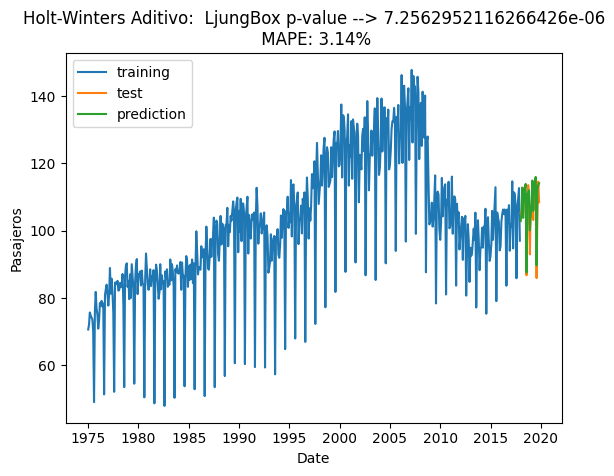

7.2562952116266426e-06


In [ ]:
eval_model(modelo_hot_winters, train, test, name='Holt-Winters Aditivo')

### Pregunta 39:

In [ ]:
modelo_sarimax1 = SARIMAX(train, order=(1, 1, 1),
                          seasonal_order=(1, 1, 1, 12)).fit()

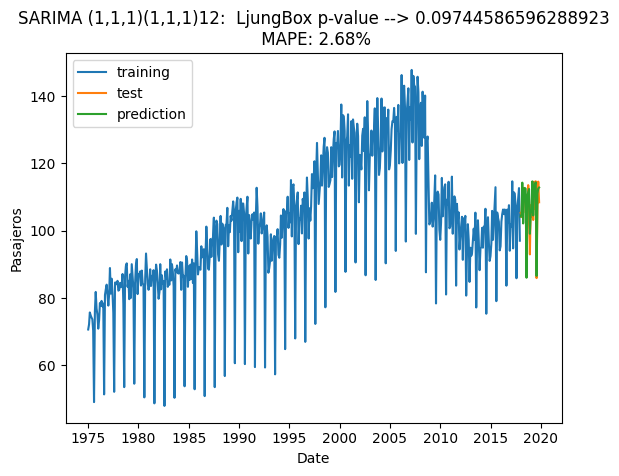

0.09744586596288923


In [ ]:
eval_model(modelo_sarimax1, train, test, name='SARIMA (1,1,1)(1,1,1)12')

### Pregunta 40:

In [ ]:
modelo_sarimax2 = SARIMAX(train, order=(1, 1, 0),
                          seasonal_order=(1, 1, 0, 12)).fit()

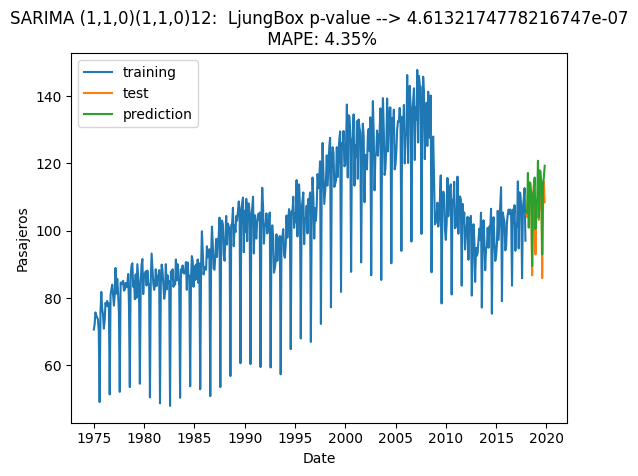

4.6132174778216747e-07


In [ ]:
eval_model(modelo_sarimax2, train, test, name='SARIMA (1,1,0)(1,1,0)12')